In [1]:
# --- Bibliothèques ---
import os, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

from utils import lire_image, lire_masque, charger_split

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Chargement des partitions (faites par Abderrahman, on ne les refait pas) ---
train_df = charger_split("train")
val_df   = charger_split("val")
test_df  = charger_split("test")

print("train :", len(train_df), "| val :", len(val_df), "| test :", len(test_df))
print("GPU disponible :", torch.cuda.is_available())

train : 533 | val : 118 | test : 111
GPU disponible : False


In [2]:
import imagehash
from PIL import Image
from tqdm import tqdm

tout_df = charger_split()   # les 778 images, toutes partitions confondues

# 1. Une empreinte perceptuelle par image
empreintes = [imagehash.phash(Image.open(p).convert("L"))
              for p in tqdm(tout_df["image_path"], desc="Calcul des phash")]

# 2. Chaque empreinte -> tableau de 64 bits (0/1)
bits = np.array([e.hash.flatten() for e in empreintes], dtype=np.uint8)

# 3. Distance de Hamming entre TOUTES les paires d'images (matrice 778 x 778)
distances = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)

# 4. On garde les paires très proches (en ne comptant chaque paire qu'une fois)
SEUIL = 6
i, j = np.where(np.triu(distances <= SEUIL, k=1))

paires = pd.DataFrame({
    "image_1": tout_df.loc[i, "id"].values,
    "split_1": tout_df.loc[i, "split"].values,
    "image_2": tout_df.loc[j, "id"].values,
    "split_2": tout_df.loc[j, "split"].values,
    "distance": distances[i, j],
}).sort_values("distance")

paires["fuite"] = paires["split_1"] != paires["split_2"]

print(f"Paires presque identiques (distance <= {SEUIL}) : {len(paires)}")
print(f"Dont à cheval entre deux partitions (fuite) : {paires['fuite'].sum()}")
paires

Calcul des phash: 100%|██████████| 762/762 [00:11<00:00, 68.47it/s] 


Paires presque identiques (distance <= 6) : 198
Dont à cheval entre deux partitions (fuite) : 4


,image_1,split_1,image_2,split_2,distance,fuite
1,benign (10),test,benign (327),test,0,False
2,benign (105),train,benign (156),train,0,False
8,benign (127),val,benign (37),val,0,False
23,benign (15),train,benign (332),train,0,False
20,benign (139),train,benign (65),train,0,False
...,...,...,...,...,...,...
136,malignant (6),val,malignant (9),val,6,False
137,malignant (7),val,malignant (8),val,6,False
138,malignant (7),val,malignant (9),val,6,False
133,malignant (34),test,malignant (92),test,6,False


Nombre de paires par distance :
distance
0    40
2    87
4    47
6    24
Name: count, dtype: int64
Fuites avec distance 0 : aucune paire ✅


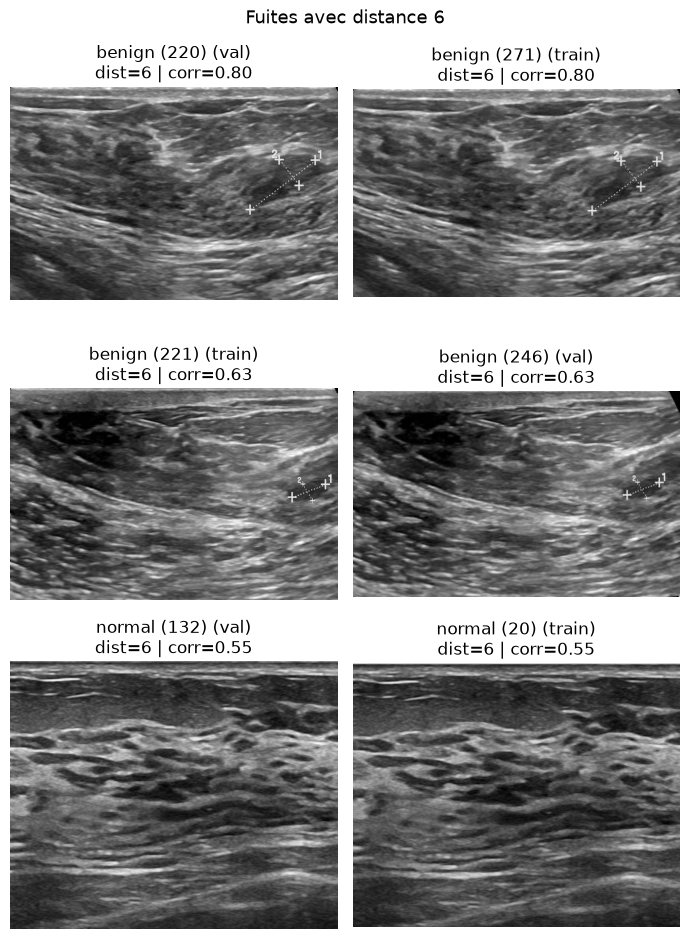

In [3]:
# 1. Combien de paires pour chaque distance ?
print("Nombre de paires par distance :")
print(paires["distance"].value_counts().sort_index())

# 2. Deuxième indice : la corrélation des pixels (1 = images identiques, 0 = sans rapport)
chemins = tout_df.set_index("id")["image_path"]

def petite_image(img_id):
    # Image réduite à 128x128 pour comparer des images de tailles différentes
    return cv2.resize(lire_image(chemins[img_id]), (128, 128)).astype(np.float32).ravel()

paires["correlation"] = [np.corrcoef(petite_image(a), petite_image(b))[0, 1]
                         for a, b in zip(paires["image_1"], paires["image_2"])]

# 3. Afficher des paires côte à côte
def afficher_paires(sous, titre):
    if len(sous) == 0:
        print(f"{titre} : aucune paire ✅")
        return
    fig, axes = plt.subplots(len(sous), 2, figsize=(7, 3.2 * len(sous)), squeeze=False)
    fig.suptitle(titre, fontsize=13)
    for k, (_, p) in enumerate(sous.iterrows()):
        for c, (img_id, split) in enumerate([(p["image_1"], p["split_1"]),
                                             (p["image_2"], p["split_2"])]):
            axes[k, c].imshow(lire_image(chemins[img_id]), cmap="gray")
            axes[k, c].set_title(f"{img_id} ({split})\ndist={p['distance']} | corr={p['correlation']:.2f}")
            axes[k, c].axis("off")
    plt.tight_layout()
    plt.show()

fuites = paires[paires["fuite"]]
afficher_paires(fuites[fuites["distance"] == 0].head(3), "Fuites avec distance 0")
afficher_paires(fuites[fuites["distance"] == 6].head(3), "Fuites avec distance 6")

Nombre de paires par distance (7 à 12) :
distance
8      6
10    10
12    21
Name: count, dtype: int64


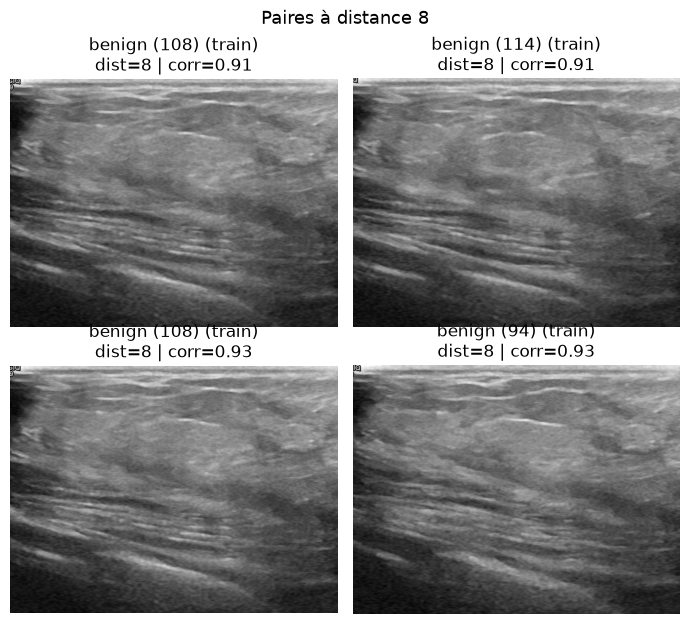

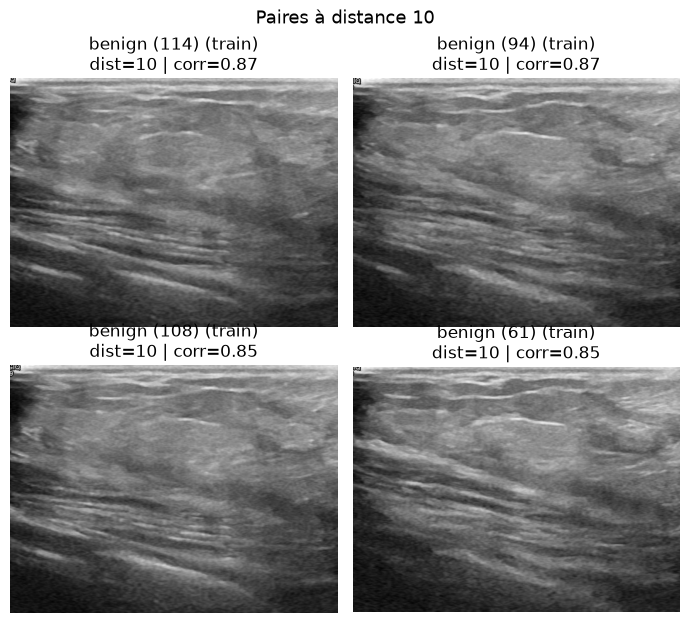

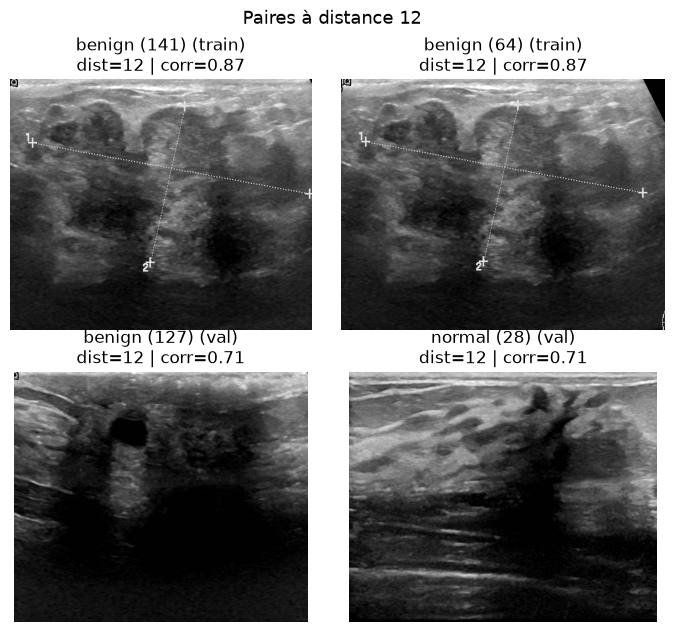

In [4]:
def construire_paires(i, j):
    # Tableau des paires (image_1, image_2) avec partition, classe et corrélation
    p = pd.DataFrame({
        "image_1": tout_df.loc[i, "id"].values,  "split_1": tout_df.loc[i, "split"].values,
        "classe_1": tout_df.loc[i, "classe"].values,
        "image_2": tout_df.loc[j, "id"].values,  "split_2": tout_df.loc[j, "split"].values,
        "classe_2": tout_df.loc[j, "classe"].values,
        "distance": distances[i, j],
    })
    p["correlation"] = [np.corrcoef(petite_image(a), petite_image(b))[0, 1]
                        for a, b in zip(p["image_1"], p["image_2"])]
    return p.sort_values("distance")

i2, j2 = np.where(np.triu((distances > 6) & (distances <= 12), k=1))
plus_loin = construire_paires(i2, j2)

print("Nombre de paires par distance (7 à 12) :")
print(plus_loin["distance"].value_counts().sort_index())

for d in [8, 10, 12]:
    afficher_paires(plus_loin[plus_loin["distance"] == d].head(2), f"Paires à distance {d}")

In [5]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# 1. Paires candidates (distance <= 12) avec leur corrélation
i3, j3 = np.where(np.triu(distances <= 12, k=1))
candidates = construire_paires(i3, j3)

# 2. Règle corrigée : distance <= 6, OU distance 7-12 avec corrélation >= 0.85
regle = (candidates["distance"] <= 6) | (candidates["correlation"] >= 0.85)
vraies = candidates[regle]
print(f"Paires candidates : {len(candidates)} | doublons : {len(vraies)} "
      f"| faux positifs écartés : {len(candidates) - len(vraies)}")

# 3. Groupes : si A~B et B~C, alors A, B, C sont la même image
pos = {img_id: k for k, img_id in enumerate(tout_df["id"])}
a = vraies["image_1"].map(pos).values
b = vraies["image_2"].map(pos).values
n = len(tout_df)
graphe = csr_matrix((np.ones(len(a)), (a, b)), shape=(n, n))
_, tout_df["groupe"] = connected_components(graphe, directed=False)

taille = tout_df.groupby("groupe")["id"].transform("size")
par_groupe = tout_df[taille > 1].groupby("groupe").agg(
    images=("id", lambda s: ", ".join(s)),
    splits=("split", lambda s: ", ".join(sorted(set(s)))),
    nb_splits=("split", "nunique"),
    nb_classes=("classe", "nunique"))

# 4. Bilan
fuites_groupes = par_groupe[par_groupe["nb_splits"] > 1]
print(f"\nImages ayant au moins un doublon : {(taille > 1).sum()}")
print(f"Groupes de doublons : {len(par_groupe)}")
print(f"Groupes à cheval entre partitions (fuite) : {len(fuites_groupes)}")
print(f"Groupes avec classes contradictoires : {(par_groupe['nb_classes'] > 1).sum()}")

# 5. Sauvegarde pour l'équipe
tout_df[taille > 1][["id", "classe", "split", "groupe"]].sort_values("groupe") \
    .to_csv(f"{OUT_DIR}/groupes_quasi_doublons.csv", index=False)

fuites_groupes[["images", "splits"]]

Paires candidates : 235 | doublons : 214 | faux positifs écartés : 21

Images ayant au moins un doublon : 308
Groupes de doublons : 136
Groupes à cheval entre partitions (fuite) : 4
Groupes avec classes contradictoires : 0


,images,splits
groupe,,
106,"benign (205), benign (262)","train, val"
123,"benign (220), benign (271)","train, val"
124,"benign (221), benign (246)","train, val"
534,"normal (132), normal (20)","train, val"


In [6]:
def metriques(pred, verite):
    """Compare un masque prédit et le masque réel (tableaux 0/1 de même taille)."""
    pred = pred.astype(bool)
    verite = verite.astype(bool)

    vp = np.logical_and(pred, verite).sum()    # tumeur bien trouvée
    fp = np.logical_and(pred, ~verite).sum()   # fausse alerte
    fn = np.logical_and(~pred, verite).sum()   # tumeur ratée

    if verite.sum() == 0:                       # image sans tumeur (classe normal)
        ok = float(pred.sum() == 0)             # 1 si rien prédit, 0 sinon
        return {"dice": ok, "iou": ok, "rappel": np.nan, "precision": ok}

    return {
        "dice":      2 * vp / (2 * vp + fp + fn),
        "iou":       vp / (vp + fp + fn),
        "rappel":    vp / (vp + fn),
        "precision": vp / (vp + fp) if (vp + fp) > 0 else 0.0,
    }

# --- Tests sur des petits masques fabriqués à la main ---
verite = np.zeros((10, 10), dtype=np.uint8)
verite[2:6, 2:6] = 1                     # une "tumeur" carrée de 16 pixels

parfait = verite.copy()                  # prédiction identique
moitie = np.zeros_like(verite)
moitie[2:6, 2:4] = 1                     # seulement la moitié gauche trouvée
vide = np.zeros_like(verite)             # rien trouvé

print("Prédiction parfaite :", metriques(parfait, verite))
print("Moitié trouvée      :", metriques(moitie, verite))
print("Rien trouvé         :", metriques(vide, verite))
print("Image normale, rien prédit :", metriques(vide, vide))
print("Image normale, fausse alerte :", metriques(moitie, vide))

Prédiction parfaite : {'dice': np.float64(1.0), 'iou': np.float64(1.0), 'rappel': np.float64(1.0), 'precision': np.float64(1.0)}
Moitié trouvée      : {'dice': np.float64(0.6666666666666666), 'iou': np.float64(0.5), 'rappel': np.float64(0.5), 'precision': np.float64(1.0)}
Rien trouvé         : {'dice': np.float64(0.0), 'iou': np.float64(0.0), 'rappel': np.float64(0.0), 'precision': 0.0}
Image normale, rien prédit : {'dice': 1.0, 'iou': 1.0, 'rappel': nan, 'precision': 1.0}
Image normale, fausse alerte : {'dice': 0.0, 'iou': 0.0, 'rappel': nan, 'precision': 0.0}


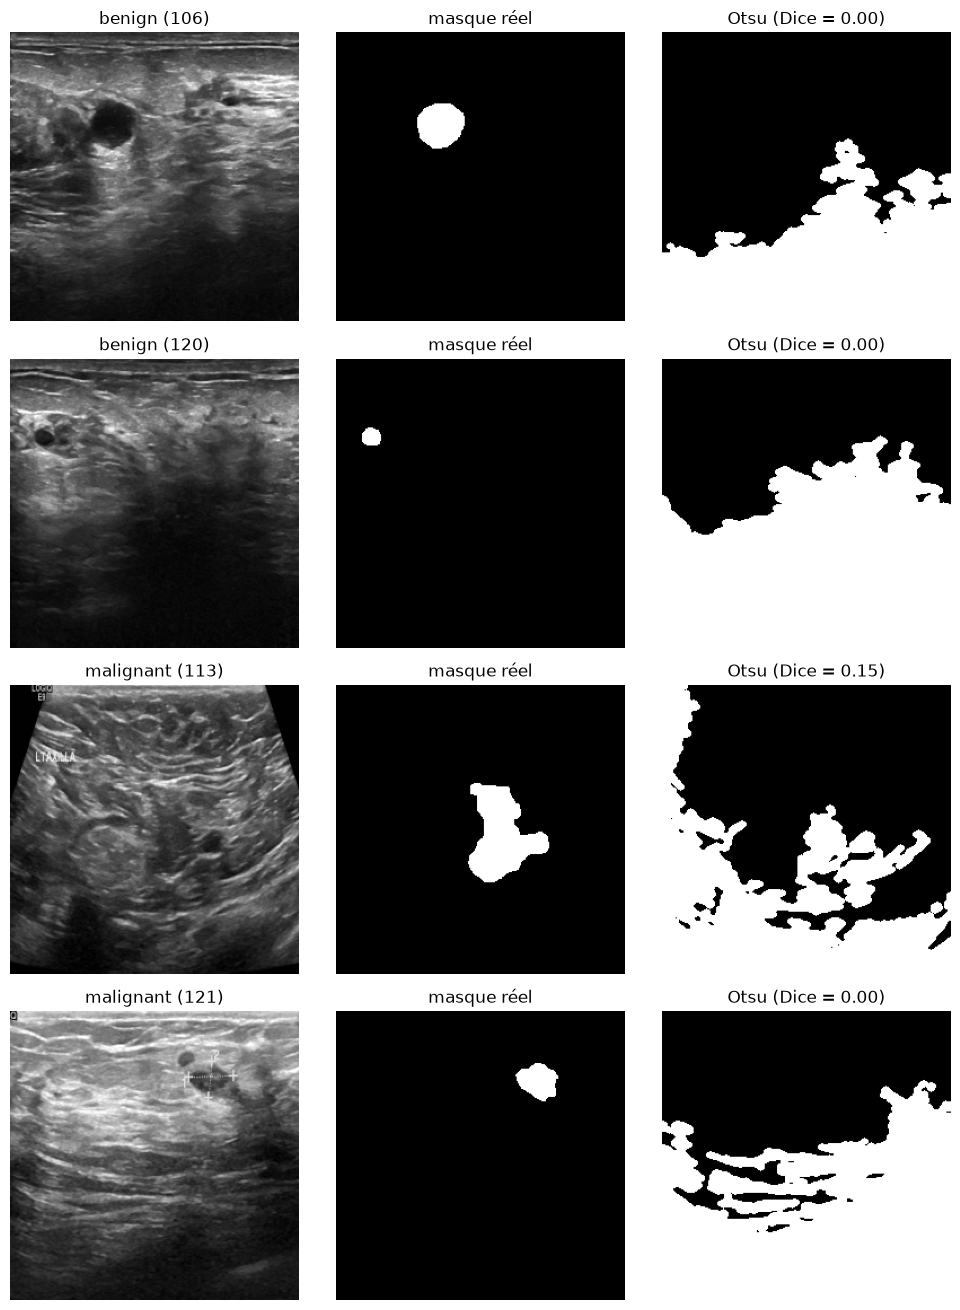

In [7]:
TAILLE = 256   # même taille que pour les modèles DL

def redimensionner(img, masque):
    # Image : interpolation classique | Masque : INTER_NEAREST pour rester en 0/1
    img = cv2.resize(img, (TAILLE, TAILLE), interpolation=cv2.INTER_AREA)
    masque = cv2.resize(masque, (TAILLE, TAILLE), interpolation=cv2.INTER_NEAREST)
    return img, masque

def otsu_segmenter(img):
    # 1. Flou pour lisser le bruit de l'échographie
    flou = cv2.GaussianBlur(img, (5, 5), 0)
    # 2. Seuil d'Otsu inversé : les zones sombres deviennent 1
    _, binaire = cv2.threshold(flou, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # 3. Ouverture : on enlève les petits points isolés
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    binaire = cv2.morphologyEx(binaire, cv2.MORPH_OPEN, noyau)
    # 4. On garde la plus grande zone
    nb, etiquettes, stats, _ = cv2.connectedComponentsWithStats(binaire)
    if nb <= 1:                                   # aucune zone trouvée
        return np.zeros_like(binaire)
    plus_grande = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return (etiquettes == plus_grande).astype(np.uint8)

# --- Visualisation sur 4 images de validation ---
exemples = val_df.groupby("classe").head(2).head(4)   # benign et malignant
fig, axes = plt.subplots(len(exemples), 3, figsize=(10, 3.3 * len(exemples)))
for k, (_, ligne) in enumerate(exemples.iterrows()):
    img, verite = redimensionner(lire_image(ligne["image_path"]),
                                 lire_masque(ligne["mask_paths"]))
    pred = otsu_segmenter(img)
    d = metriques(pred, verite)["dice"]
    axes[k, 0].imshow(img, cmap="gray");    axes[k, 0].set_title(f"{ligne['id']}")
    axes[k, 1].imshow(verite, cmap="gray"); axes[k, 1].set_title("masque réel")
    axes[k, 2].imshow(pred, cmap="gray");   axes[k, 2].set_title(f"Otsu (Dice = {d:.2f})")
    for ax in axes[k]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/otsu_exemples.png", dpi=150)
plt.show()

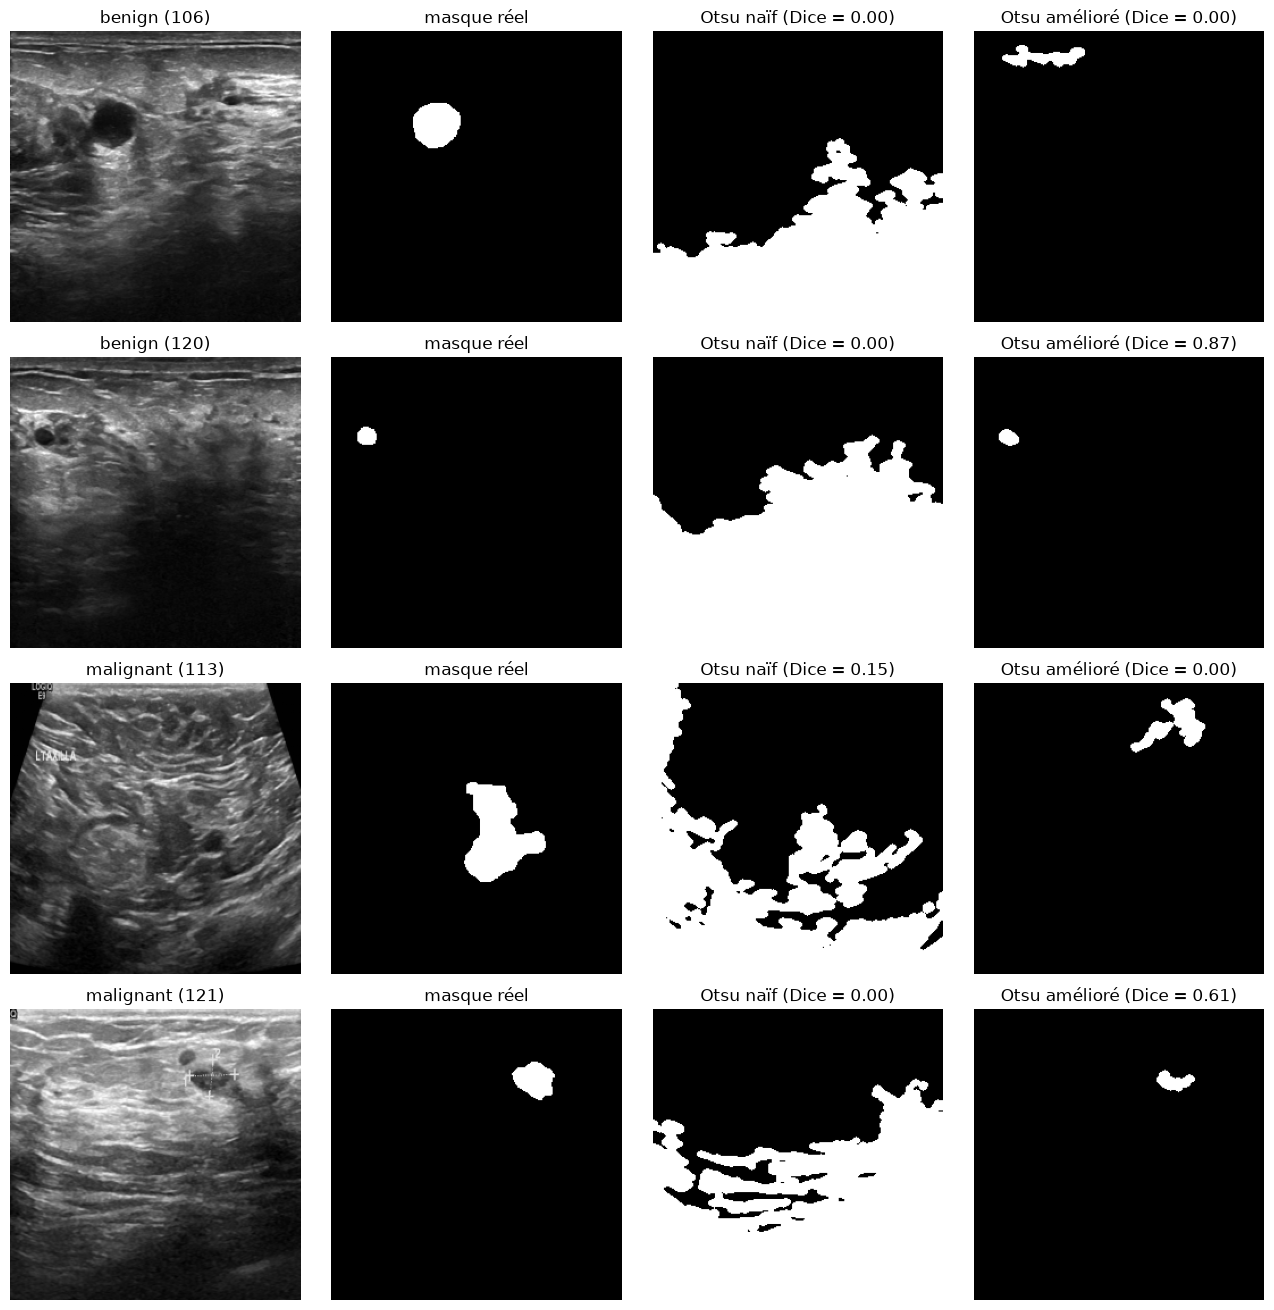

In [8]:
def otsu_ameliore(img):
    # Étapes 1 à 3 identiques : flou, seuil d'Otsu inversé, ouverture
    flou = cv2.GaussianBlur(img, (5, 5), 0)
    _, binaire = cv2.threshold(flou, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    binaire = cv2.morphologyEx(binaire, cv2.MORPH_OPEN, noyau)

    # Étape 4 améliorée : on ignore les zones qui touchent le bord de l'image
    nb, etiquettes, stats, _ = cv2.connectedComponentsWithStats(binaire)
    h, w = binaire.shape
    meilleure, meilleure_aire = None, 0
    for k in range(1, nb):
        x, y, larg, haut, aire = stats[k]
        touche_bord = x == 0 or y == 0 or x + larg >= w or y + haut >= h
        if not touche_bord and aire > meilleure_aire:
            meilleure, meilleure_aire = k, aire

    if meilleure is None:                       # aucune zone valable
        return np.zeros_like(binaire)
    return (etiquettes == meilleure).astype(np.uint8)

# --- Comparaison des deux versions sur les mêmes exemples ---
fig, axes = plt.subplots(len(exemples), 4, figsize=(13, 3.3 * len(exemples)))
for k, (_, ligne) in enumerate(exemples.iterrows()):
    img, verite = redimensionner(lire_image(ligne["image_path"]),
                                 lire_masque(ligne["mask_paths"]))
    p1, p2 = otsu_segmenter(img), otsu_ameliore(img)
    axes[k, 0].imshow(img, cmap="gray");    axes[k, 0].set_title(ligne["id"])
    axes[k, 1].imshow(verite, cmap="gray"); axes[k, 1].set_title("masque réel")
    axes[k, 2].imshow(p1, cmap="gray")
    axes[k, 2].set_title(f"Otsu naïf (Dice = {metriques(p1, verite)['dice']:.2f})")
    axes[k, 3].imshow(p2, cmap="gray")
    axes[k, 3].set_title(f"Otsu amélioré (Dice = {metriques(p2, verite)['dice']:.2f})")
    for ax in axes[k]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/otsu_naif_vs_ameliore.png", dpi=150)
plt.show()

In [9]:
import time

def evaluer_otsu(fonction, df, nom):
    lignes = []
    for _, ligne in tqdm(df.iterrows(), total=len(df), desc=nom):
        img, verite = redimensionner(lire_image(ligne["image_path"]),
                                     lire_masque(ligne["mask_paths"]))
        debut = time.perf_counter()
        pred = fonction(img)
        duree_ms = (time.perf_counter() - debut) * 1000
        lignes.append({"modele": nom, "id": ligne["id"], "classe": ligne["classe"],
                       **metriques(pred, verite), "temps_ms": duree_ms})
    return pd.DataFrame(lignes)

res_otsu = pd.concat([
    evaluer_otsu(otsu_segmenter, test_df, "Otsu naïf"),
    evaluer_otsu(otsu_ameliore,  test_df, "Otsu amélioré"),
])

# Sauvegarde image par image (utile pour l'analyse d'erreurs d'Abderrahman)
res_otsu.to_csv(f"{OUT_DIR}/resultats_otsu_test.csv", index=False)

cols = ["dice", "iou", "rappel", "precision", "temps_ms"]
print("=== Moyenne sur tout le test ===")
display(res_otsu.groupby("modele")[cols].mean().round(3))

print("=== Images avec tumeur seulement (benign + malignant) ===")
display(res_otsu[res_otsu["classe"] != "normal"].groupby("modele")[cols].mean().round(3))

print("=== Dice par classe ===")
display(res_otsu.pivot_table(index="modele", columns="classe", values="dice").round(3))

Otsu amélioré: 100%|██████████| 111/111 [00:02<00:00, 52.23it/s]

=== Moyenne sur tout le test ===


,dice,iou,rappel,precision,temps_ms
modele,,,,,
Otsu amélioré,0.124,0.094,0.139,0.276,1.575
Otsu naïf,0.169,0.113,0.439,0.124,2.223


=== Images avec tumeur seulement (benign + malignant) ===


,dice,iou,rappel,precision,temps_ms
modele,,,,,
Otsu amélioré,0.148,0.113,0.139,0.330,1.558
Otsu naïf,0.202,0.135,0.439,0.148,2.295


=== Dice par classe ===


classe,benign,malignant,normal
modele,,,
Otsu amélioré,0.163,0.119,0.0
Otsu naïf,0.150,0.304,0.0


In [10]:
from torch.utils.data import Dataset, DataLoader

class BUSIDataset(Dataset):
    """Fournit au réseau des paires (image, masque) en 256x256, prêtes pour PyTorch."""

    def __init__(self, df, augmenter=False):
        self.df = df.reset_index(drop=True)
        self.augmenter = augmenter

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        ligne = self.df.iloc[idx]
        img, masque = redimensionner(lire_image(ligne["image_path"]),
                                     lire_masque(ligne["mask_paths"]))
        img = img.astype(np.float32) / 255.0          # pixels entre 0 et 1
        masque = masque.astype(np.float32)

        if self.augmenter and random.random() < 0.5:  # miroir gauche-droite
            img, masque = img[:, ::-1].copy(), masque[:, ::-1].copy()

        # PyTorch attend la forme (canaux, hauteur, largeur) -> (1, 256, 256)
        return torch.from_numpy(img)[None], torch.from_numpy(masque)[None]

BATCH = 8
train_loader = DataLoader(BUSIDataset(train_df, augmenter=True), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(BUSIDataset(val_df),  batch_size=BATCH)
test_loader  = DataLoader(BUSIDataset(test_df), batch_size=BATCH)

# Vérification : un lot d'images
images, masques = next(iter(train_loader))
print("Lot d'images :", images.shape, "| min/max :", images.min().item(), images.max().item())
print("Lot de masques :", masques.shape, "| valeurs :", masques.unique().tolist())
print("Nombre de lots par époque :", len(train_loader))

Lot d'images : torch.Size([8, 1, 256, 256]) | min/max : 0.0 1.0
Lot de masques : torch.Size([8, 1, 256, 256]) | valeurs : [0.0, 1.0]
Nombre de lots par époque : 67


In [11]:
import torch.nn as nn

def bloc_conv(entree, sortie):
    # Deux convolutions 3x3, chacune suivie de BatchNorm + ReLU
    return nn.Sequential(
        nn.Conv2d(entree, sortie, 3, padding=1), nn.BatchNorm2d(sortie), nn.ReLU(inplace=True),
        nn.Conv2d(sortie, sortie, 3, padding=1), nn.BatchNorm2d(sortie), nn.ReLU(inplace=True),
    )

class CNNSimple(nn.Module):
    """Encodeur-décodeur SANS skip connections (baseline face à U-Net)."""

    def __init__(self, f=16):
        super().__init__()
        # --- Encodeur : on réduit la taille, on augmente le nombre de filtres ---
        self.enc1, self.enc2 = bloc_conv(1, f),       bloc_conv(f, 2 * f)
        self.enc3, self.enc4 = bloc_conv(2 * f, 4 * f), bloc_conv(4 * f, 8 * f)
        self.pool = nn.MaxPool2d(2)
        # --- Centre ---
        self.centre = bloc_conv(8 * f, 16 * f)
        # --- Décodeur : on agrandit, sans rien recevoir de l'encodeur ---
        self.up4, self.dec4 = nn.ConvTranspose2d(16 * f, 8 * f, 2, stride=2), bloc_conv(8 * f, 8 * f)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * f, 4 * f, 2, stride=2),  bloc_conv(4 * f, 4 * f)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * f, 2 * f, 2, stride=2),  bloc_conv(2 * f, 2 * f)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * f, f, 2, stride=2),      bloc_conv(f, f)
        # --- Sortie : 1 score par pixel ---
        self.sortie = nn.Conv2d(f, 1, 1)

    def forward(self, x):
        x = self.pool(self.enc1(x))    # 256 -> 128
        x = self.pool(self.enc2(x))    # 128 -> 64
        x = self.pool(self.enc3(x))    # 64  -> 32
        x = self.pool(self.enc4(x))    # 32  -> 16
        x = self.centre(x)
        x = self.dec4(self.up4(x))     # 16  -> 32
        x = self.dec3(self.up3(x))     # 32  -> 64
        x = self.dec2(self.up2(x))     # 64  -> 128
        x = self.dec1(self.up1(x))     # 128 -> 256
        return self.sortie(x)          # scores bruts (logits), pas encore de sigmoïde

# --- Vérifications ---
modele = CNNSimple()
nb_params = sum(p.numel() for p in modele.parameters())
print(f"Nombre de paramètres : {nb_params:,}")

with torch.no_grad():
    sortie = modele(images)            # le lot de la cellule 10
print("Entrée :", images.shape, "-> Sortie :", sortie.shape)

Nombre de paramètres : 1,747,921
Entrée : torch.Size([8, 1, 256, 256]) -> Sortie : torch.Size([8, 1, 256, 256])


In [12]:
import copy

# --- Fonction de perte : BCE + Dice ---
bce = nn.BCEWithLogitsLoss()

def perte_dice(logits, cible, eps=1.0):
    proba = torch.sigmoid(logits)
    inter = (proba * cible).sum(dim=(1, 2, 3))
    total = proba.sum(dim=(1, 2, 3)) + cible.sum(dim=(1, 2, 3))
    return (1 - (2 * inter + eps) / (total + eps)).mean()

def perte_bce_dice(logits, cible):
    return bce(logits, cible) + perte_dice(logits, cible)

# --- Dice de validation, calculé avec NOTRE fonction metriques (comme pour Otsu) ---
def dice_moyen(modele, loader):
    modele.eval()
    scores = []
    with torch.no_grad():
        for x, y in loader:
            pred = (torch.sigmoid(modele(x)) > 0.5).numpy()
            for p, v in zip(pred, y.numpy()):
                scores.append(metriques(p[0], v[0])["dice"])
    return float(np.mean(scores))

# --- Entraînement ---
torch.manual_seed(SEED)
modele = CNNSimple()
optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)

NB_EPOQUES, PATIENCE = 40, 7
historique = []
meilleur_dice, meilleurs_poids, sans_progres = -1, None, 0
debut_total = time.perf_counter()

for epoque in range(1, NB_EPOQUES + 1):
    debut = time.perf_counter()

    # 1. Apprentissage sur le train
    modele.train()
    pertes = []
    for x, y in train_loader:
        optimiseur.zero_grad()
        perte = perte_bce_dice(modele(x), y)
        perte.backward()                 # rétropropagation
        optimiseur.step()                # correction des poids
        pertes.append(perte.item())

    # 2. Évaluation sur la validation
    modele.eval()
    with torch.no_grad():
        perte_val = np.mean([perte_bce_dice(modele(x), y).item() for x, y in val_loader])
    dice_val = dice_moyen(modele, val_loader)

    historique.append({"epoque": epoque, "perte_train": np.mean(pertes),
                       "perte_val": perte_val, "dice_val": dice_val})
    print(f"Époque {epoque:2d} | perte train {np.mean(pertes):.3f} | perte val {perte_val:.3f} "
          f"| Dice val {dice_val:.3f} | {time.perf_counter() - debut:.0f} s")

    # 3. Sauvegarde du meilleur modèle + early stopping
    if dice_val > meilleur_dice:
        meilleur_dice, meilleurs_poids, sans_progres = dice_val, copy.deepcopy(modele.state_dict()), 0
    else:
        sans_progres += 1
        if sans_progres >= PATIENCE:
            print(f"Arrêt anticipé : pas d'amélioration depuis {PATIENCE} époques.")
            break

temps_entrainement = time.perf_counter() - debut_total
modele.load_state_dict(meilleurs_poids)
os.makedirs("modeles", exist_ok=True)
torch.save(meilleurs_poids, "modeles/cnn_simple.pth")
pd.DataFrame(historique).to_csv(f"{OUT_DIR}/historique_cnn_simple.csv", index=False)

print(f"\nMeilleur Dice de validation : {meilleur_dice:.3f}")
print(f"Temps d'entraînement : {temps_entrainement / 60:.1f} min")

Époque  1 | perte train 1.196 | perte val 1.150 | Dice val 0.419 | 228 s
Époque  2 | perte train 1.019 | perte val 1.262 | Dice val 0.338 | 242 s
Époque  3 | perte train 0.913 | perte val 1.054 | Dice val 0.316 | 231 s
Époque  4 | perte train 0.827 | perte val 0.930 | Dice val 0.534 | 157 s
Époque  5 | perte train 0.762 | perte val 0.853 | Dice val 0.481 | 132 s
Époque  6 | perte train 0.727 | perte val 0.887 | Dice val 0.523 | 142 s
Époque  7 | perte train 0.692 | perte val 0.883 | Dice val 0.424 | 147 s
Époque  8 | perte train 0.684 | perte val 0.857 | Dice val 0.532 | 148 s
Époque  9 | perte train 0.664 | perte val 0.838 | Dice val 0.502 | 147 s
Époque 10 | perte train 0.625 | perte val 0.753 | Dice val 0.576 | 149 s
Époque 11 | perte train 0.627 | perte val 0.744 | Dice val 0.568 | 144 s
Époque 12 | perte train 0.598 | perte val 0.730 | Dice val 0.615 | 143 s
Époque 13 | perte train 0.585 | perte val 0.888 | Dice val 0.444 | 156 s
Époque 14 | perte train 0.561 | perte val 0.796 | D

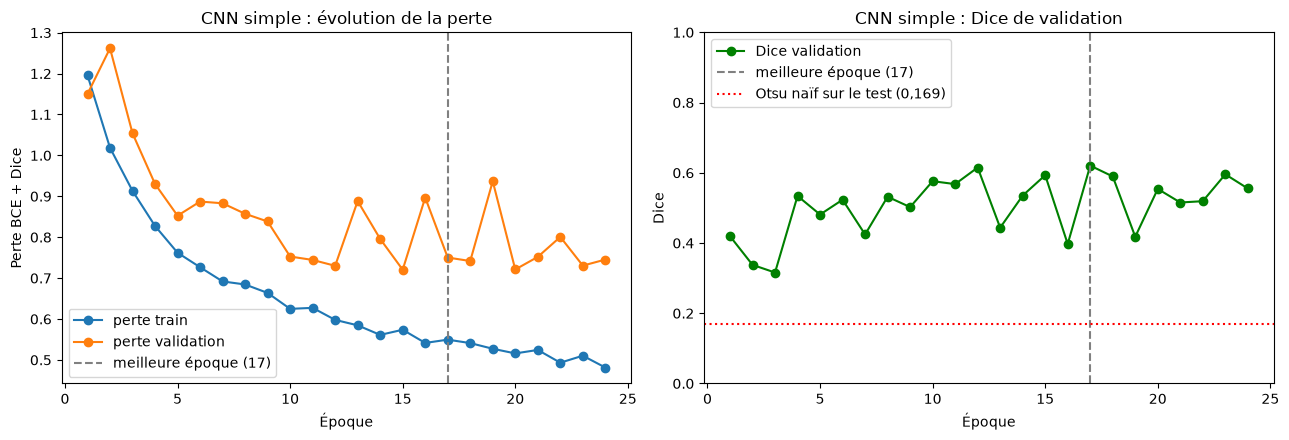

In [13]:
hist = pd.DataFrame(historique)
meilleure = hist.loc[hist["dice_val"].idxmax(), "epoque"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Les pertes
axes[0].plot(hist["epoque"], hist["perte_train"], "o-", label="perte train")
axes[0].plot(hist["epoque"], hist["perte_val"], "o-", label="perte validation")
axes[0].axvline(meilleure, color="gray", linestyle="--", label=f"meilleure époque ({meilleure})")
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Perte BCE + Dice")
axes[0].set_title("CNN simple : évolution de la perte")
axes[0].legend()

# 2. Le Dice de validation
axes[1].plot(hist["epoque"], hist["dice_val"], "o-", color="green", label="Dice validation")
axes[1].axvline(meilleure, color="gray", linestyle="--", label=f"meilleure époque ({meilleure})")
axes[1].axhline(0.169, color="red", linestyle=":", label="Otsu naïf sur le test (0,169)")
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Dice")
axes[1].set_ylim(0, 1)
axes[1].set_title("CNN simple : Dice de validation")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/courbes_cnn_simple.png", dpi=150)
plt.show()

In [14]:
def evaluer_cnn(modele, df, nom):
    modele.eval()
    lignes = []
    with torch.no_grad():
        for _, ligne in tqdm(df.iterrows(), total=len(df), desc=nom):
            img, verite = redimensionner(lire_image(ligne["image_path"]),
                                         lire_masque(ligne["mask_paths"]))
            x = torch.from_numpy(img.astype(np.float32) / 255.0)[None, None]  # (1, 1, 256, 256)
            debut = time.perf_counter()
            pred = (torch.sigmoid(modele(x)) > 0.5).numpy()[0, 0]
            duree_ms = (time.perf_counter() - debut) * 1000
            lignes.append({"modele": nom, "id": ligne["id"], "classe": ligne["classe"],
                           **metriques(pred, verite), "temps_ms": duree_ms})
    return pd.DataFrame(lignes)

res_cnn = evaluer_cnn(modele, test_df, "CNN simple")
res_cnn.to_csv(f"{OUT_DIR}/resultats_cnn_simple_test.csv", index=False)

# --- Tableau comparatif : Otsu naïf, Otsu amélioré, CNN simple ---
tous = pd.concat([res_otsu, res_cnn])
ordre_modeles = ["Otsu naïf", "Otsu amélioré", "CNN simple"]
cols = ["dice", "iou", "rappel", "precision", "temps_ms"]

print("=== Moyenne sur tout le test ===")
display(tous.groupby("modele")[cols].mean().reindex(ordre_modeles).round(3))

print("=== Images avec tumeur seulement ===")
display(tous[tous["classe"] != "normal"].groupby("modele")[cols].mean().reindex(ordre_modeles).round(3))

print("=== Dice par classe ===")
display(tous.pivot_table(index="modele", columns="classe", values="dice").reindex(ordre_modeles).round(3))

tous.to_csv(f"{OUT_DIR}/resultats_baselines_test.csv", index=False)

CNN simple: 100%|██████████| 111/111 [00:07<00:00, 15.24it/s]

=== Moyenne sur tout le test ===


,dice,iou,rappel,precision,temps_ms
modele,,,,,
Otsu naïf,0.169,0.113,0.439,0.124,2.223
Otsu amélioré,0.124,0.094,0.139,0.276,1.575
CNN simple,0.722,0.631,0.715,0.766,54.529


=== Images avec tumeur seulement ===


,dice,iou,rappel,precision,temps_ms
modele,,,,,
Otsu naïf,0.202,0.135,0.439,0.148,2.295
Otsu amélioré,0.148,0.113,0.139,0.330,1.558
CNN simple,0.679,0.571,0.715,0.732,54.044


=== Dice par classe ===


classe,benign,malignant,normal
modele,,,
Otsu naïf,0.150,0.304,0.000
Otsu amélioré,0.163,0.119,0.000
CNN simple,0.740,0.556,0.944


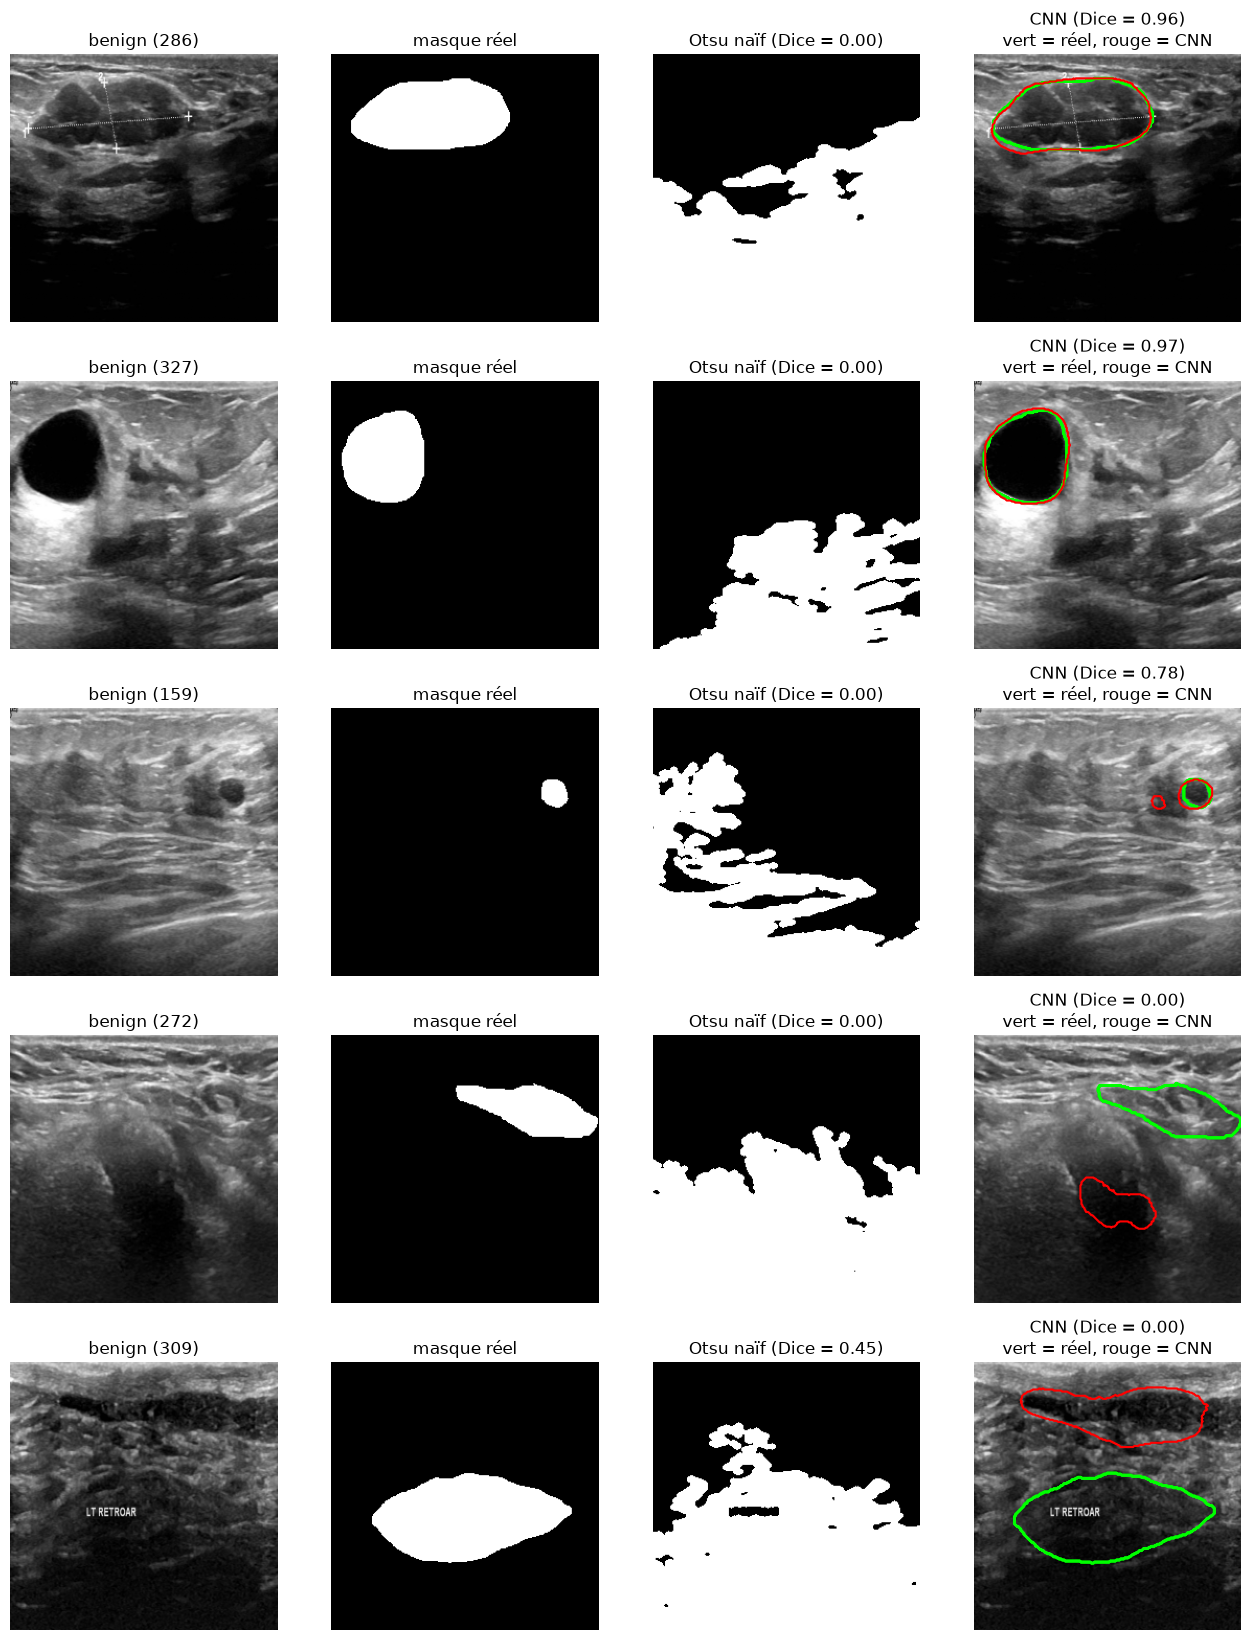

In [15]:
avec_tumeur = res_cnn[res_cnn["classe"] != "normal"].sort_values("dice")
choix = pd.concat([
    avec_tumeur.tail(2),                                        # 2 meilleures
    avec_tumeur.iloc[[len(avec_tumeur) // 2]],                  # 1 moyenne
    avec_tumeur.head(2),                                        # 2 pires
])["id"]

infos = test_df.set_index("id")
otsu_dice = res_otsu[res_otsu["modele"] == "Otsu naïf"].set_index("id")["dice"]

fig, axes = plt.subplots(len(choix), 4, figsize=(13, 3.3 * len(choix)))
modele.eval()
for k, img_id in enumerate(choix):
    ligne = infos.loc[img_id]
    img, verite = redimensionner(lire_image(ligne["image_path"]), lire_masque(ligne["mask_paths"]))
    with torch.no_grad():
        x = torch.from_numpy(img.astype(np.float32) / 255.0)[None, None]
        pred_cnn = (torch.sigmoid(modele(x)) > 0.5).numpy()[0, 0]

    axes[k, 0].imshow(img, cmap="gray");        axes[k, 0].set_title(f"{img_id}")
    axes[k, 1].imshow(verite, cmap="gray");     axes[k, 1].set_title("masque réel")
    axes[k, 2].imshow(otsu_segmenter(img), cmap="gray")
    axes[k, 2].set_title(f"Otsu naïf (Dice = {otsu_dice[img_id]:.2f})")
    axes[k, 3].imshow(img, cmap="gray")
    axes[k, 3].contour(verite, colors="lime", linewidths=1.5)    # contour réel en vert
    axes[k, 3].contour(pred_cnn, colors="red", linewidths=1.5)   # contour CNN en rouge
    axes[k, 3].set_title(f"CNN (Dice = {metriques(pred_cnn, verite)['dice']:.2f})\nvert = réel, rouge = CNN")
    for ax in axes[k]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/comparaison_otsu_cnn.png", dpi=150)
plt.show()

In [16]:
%%writefile -a utils.py


# ---------------------------------------------------------------
# Ajouté par Hiba (notebook 02) : prétraitement et métriques communs
# ---------------------------------------------------------------

def redimensionner(img, masque, taille=256):
    # Image : INTER_AREA | Masque : INTER_NEAREST pour rester en 0/1
    img = cv2.resize(img, (taille, taille), interpolation=cv2.INTER_AREA)
    masque = cv2.resize(masque, (taille, taille), interpolation=cv2.INTER_NEAREST)
    return img, masque


def metriques(pred, verite):
    """Compare un masque prédit et le masque réel (tableaux 0/1 de même taille).
    Image sans tumeur : Dice = IoU = 1 si rien n'est prédit, 0 sinon ; rappel = NaN."""
    pred = pred.astype(bool)
    verite = verite.astype(bool)
    vp = np.logical_and(pred, verite).sum()
    fp = np.logical_and(pred, ~verite).sum()
    fn = np.logical_and(~pred, verite).sum()

    if verite.sum() == 0:
        ok = float(pred.sum() == 0)
        return {"dice": ok, "iou": ok, "rappel": np.nan, "precision": ok}

    return {
        "dice":      2 * vp / (2 * vp + fp + fn),
        "iou":       vp / (vp + fp + fn),
        "rappel":    vp / (vp + fn),
        "precision": vp / (vp + fp) if (vp + fp) > 0 else 0.0,
    }

Appending to utils.py


In [19]:
import importlib, utils
importlib.reload(utils)

# 1. Les 5 fonctions sont-elles présentes ?
print([f for f in ["lire_image", "lire_masque", "charger_split", "redimensionner", "metriques"]
       if hasattr(utils, f)])

# 2. Même résultat entre utils.py et le notebook ? (masques de test recréés ici)
vrai_test = np.zeros((10, 10), dtype=np.uint8)
vrai_test[2:6, 2:6] = 1
pred_test = np.zeros_like(vrai_test)
pred_test[2:6, 2:4] = 1

print("utils.py :", utils.metriques(pred_test, vrai_test))
print("notebook :", metriques(pred_test, vrai_test))
print("Identiques :", utils.metriques(pred_test, vrai_test) == metriques(pred_test, vrai_test))

['lire_image', 'lire_masque', 'charger_split', 'redimensionner', 'metriques']
utils.py : {'dice': np.float64(0.6666666666666666), 'iou': np.float64(0.5), 'rappel': np.float64(0.5), 'precision': np.float64(1.0)}
notebook : {'dice': np.float64(0.6666666666666666), 'iou': np.float64(0.5), 'rappel': np.float64(0.5), 'precision': np.float64(1.0)}
Identiques : True
